# Question 1 — Correlation Between Daily Social Media Usage and Mental Health Score

**Research question:** Is there a correlation between the number of daily social media usage hours and the student's mental health score?

We examine whether spending more time on social media is associated with higher, lower, or no change in `Mental_Health_Score`, using correlation tests, visualisations, a simple linear regression model, and a subgroup breakdown.

## 0. Setup & Data Loading

In [13]:
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score, mean_squared_error

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110

# Cleaned dataset exported by data_exploration/01_data_overview_and_distributions.ipynb
# (exact duplicate rows removed, negative values clipped to 0)
DATA_PATH = '../dataset/student_social_media_cleaned.csv'
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f'{DATA_PATH} not found — run data_exploration/01_data_overview_and_distributions.ipynb first'
    )
df = pd.read_csv(DATA_PATH)

STRESS_ORDER = ['Low', 'Medium', 'High', 'Very High']
df['Stress_Level'] = pd.Categorical(df['Stress_Level'], categories=STRESS_ORDER, ordered=True)

X_COL = 'Avg_Daily_Usage_Hours'
Y_COL = 'Mental_Health_Score'

print('Shape:', df.shape)
df[[X_COL, Y_COL]].describe()

Shape: (4998, 13)


,Avg_Daily_Usage_Hours,Mental_Health_Score
count,4998.000000,4998.000000
mean,5.078491,6.231152
std,1.654097,1.278476
min,1.000000,3.600000
25%,3.800000,5.100000
50%,5.000000,6.100000
75%,6.300000,7.100000
max,8.800000,9.400000


## 1. Variable Overview & Normality Check

**Understanding the p-value.** Each test below starts from a *null hypothesis* — here that the variable **is normally distributed**. The **p-value** is the probability of seeing data this far from a normal shape purely by chance *if that null hypothesis were true*.

- **p > 0.05** → not enough evidence to reject → treat as **Normal**
- **p ≤ 0.05** → strong evidence against the null → **Not normal**

`α = 0.05` is the 5% significance threshold we compare the p-value against.

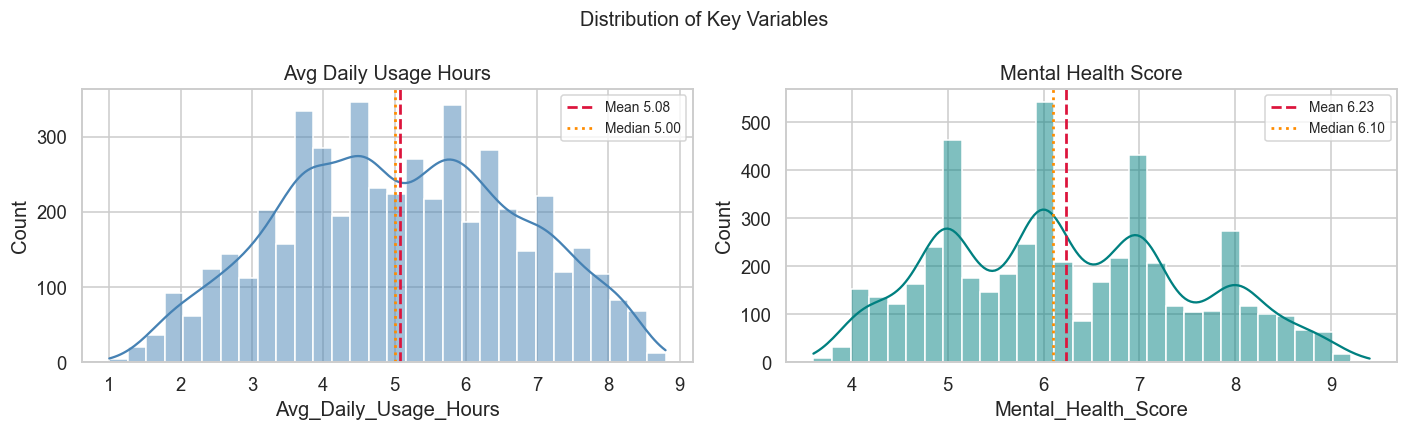

Avg_Daily_Usage_Hours: stat=362.323, p=2.102e-79  → Not normal (α=0.05)
Mental_Health_Score: stat=462.316, p=4.068e-101  → Not normal (α=0.05)


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col, color in zip(axes, [X_COL, Y_COL], ['steelblue', 'teal']):
    sns.histplot(df[col], kde=True, bins=30, color=color, edgecolor='white', ax=ax)
    ax.axvline(df[col].mean(),   color='crimson',    lw=1.8, linestyle='--', label=f'Mean {df[col].mean():.2f}')
    ax.axvline(df[col].median(), color='darkorange', lw=1.8, linestyle=':',  label=f'Median {df[col].median():.2f}')
    ax.set_title(col.replace('_', ' '))
    ax.legend(fontsize=9)

fig.suptitle('Distribution of Key Variables', fontsize=13)
plt.tight_layout()
plt.show()

# Normality tests (D'Agostino-Pearson — works for n > 20)
for col in [X_COL, Y_COL]:
    stat, p = stats.normaltest(df[col])
    print(f'{col}: stat={stat:.3f}, p={p:.3e}  → {"Normal" if p > 0.05 else "Not normal"} (α=0.05)')

## 2. Correlation Analysis

We report both **Pearson** (linear) and **Spearman** (rank-based, robust to non-normality) correlations.

**Understanding the p-value.** For a correlation, the *null hypothesis* is that there is **no relationship** between the two variables (true correlation = 0). The **p-value** is the probability of observing a correlation at least this strong by chance if that null were true.

- **p ≤ 0.05** → the correlation is **statistically significant** (unlikely to be a fluke)
- **p > 0.05** → not enough evidence that a real relationship exists

In [15]:
pearson_r,  pearson_p  = stats.pearsonr( df[X_COL], df[Y_COL])
spearman_r, spearman_p = stats.spearmanr(df[X_COL], df[Y_COL])

def interpret_r(r):
    a = abs(r)
    if a < 0.1:  return 'negligible'
    if a < 0.3:  return 'weak'
    if a < 0.5:  return 'moderate'
    if a < 0.7:  return 'strong'
    return 'very strong'

results = pd.DataFrame({
    'Method':    ['Pearson', 'Spearman'],
    'r':         [round(pearson_r,  4), round(spearman_r,  4)],
    'p-value':   [pearson_p,            spearman_p],
    'Significant (α=0.05)': [pearson_p < 0.05, spearman_p < 0.05],
    'Interpretation': [interpret_r(pearson_r), interpret_r(spearman_r)],
})

print(results.to_string(index=False))

  Method       r  p-value  Significant (α=0.05) Interpretation
 Pearson -0.8165      0.0                  True    very strong
Spearman -0.8401      0.0                  True    very strong


## 3. Scatter Plot with Regression Line

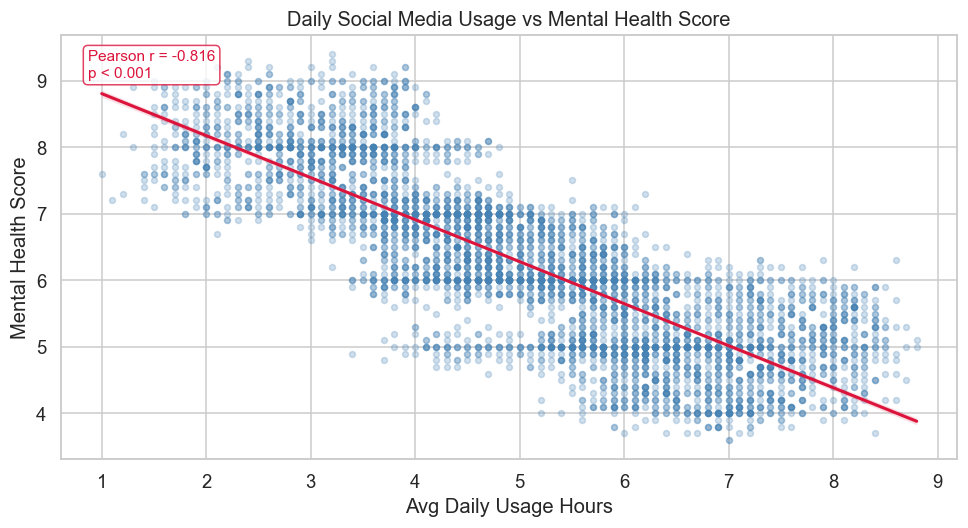

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.regplot(
    x=X_COL, y=Y_COL, data=df, ax=ax,
    scatter_kws={'alpha': 0.25, 's': 15, 'color': 'steelblue'},
    line_kws={'color': 'crimson', 'lw': 2}
)

ax.set_title('Daily Social Media Usage vs Mental Health Score')
ax.set_xlabel('Avg Daily Usage Hours')
ax.set_ylabel('Mental Health Score')

significance = 'p < 0.001' if pearson_p < 0.001 else f'p = {pearson_p:.3f}'
ax.annotate(
    f'Pearson r = {pearson_r:.3f}\n{significance}',
    xy=(0.03, 0.90), xycoords='axes fraction',
    fontsize=10, color='crimson',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='crimson', alpha=0.8)
)

plt.tight_layout()
plt.show()

## 4. Binned Box Plot

Grouping usage hours into **one-hour bins** reveals the trend more clearly than individual points.

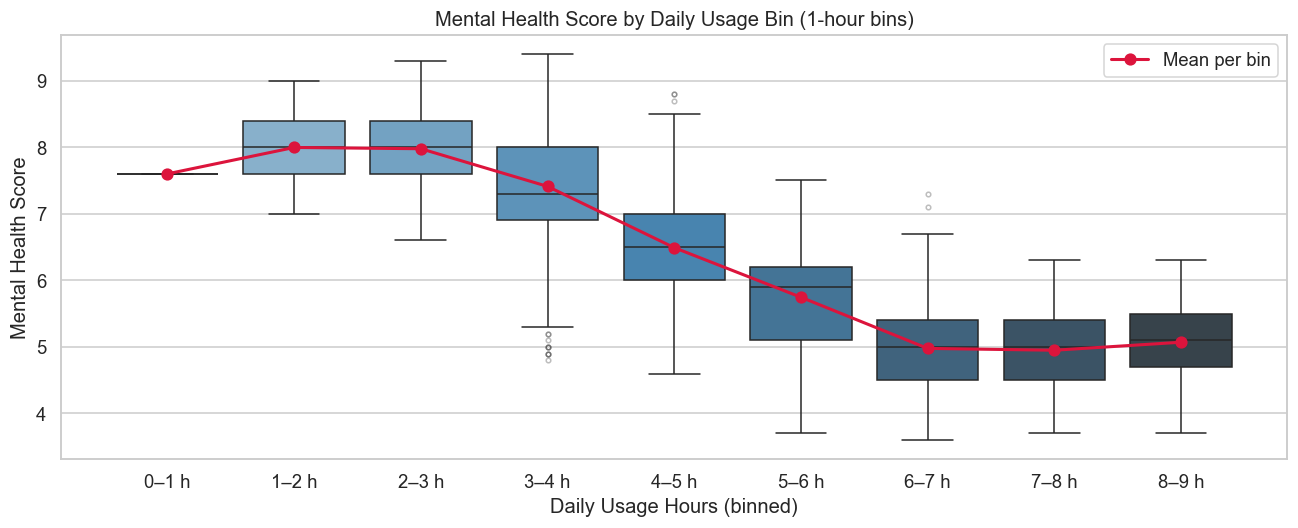

Mean Mental Health Score per bin:
Usage_Bin
0–1 h    7.600000
1–2 h    7.996053
2–3 h    7.977149
3–4 h    7.411285
4–5 h    6.490792
5–6 h    5.746116
6–7 h    4.977210
7–8 h    4.949621
8–9 h    5.069939


In [17]:
import math

# One-hour-wide bins covering the full usage range
max_edge = math.ceil(df[X_COL].max())
edges = list(range(0, max_edge + 1))                      # 0, 1, 2, ..., max
bin_order = [f'{lo}\u2013{lo + 1} h' for lo in edges[:-1]]  # '0\u20131 h', '1\u20132 h', ...

df['Usage_Bin'] = pd.cut(
    df[X_COL],
    bins=edges,
    labels=bin_order,
    include_lowest=True
)

bin_means = df.groupby('Usage_Bin', observed=True)[Y_COL].mean()

fig, ax = plt.subplots(figsize=(12, 5))

sns.boxplot(
    data=df, x='Usage_Bin', y=Y_COL, order=bin_order,
    palette='Blues_d', ax=ax,
    flierprops=dict(marker='o', markersize=3, alpha=0.3)
)
ax.plot(
    range(len(bin_order)), [bin_means.get(b, float('nan')) for b in bin_order],
    'o-', color='crimson', lw=2, markersize=7, label='Mean per bin', zorder=5
)
ax.set_title('Mental Health Score by Daily Usage Bin (1-hour bins)')
ax.set_xlabel('Daily Usage Hours (binned)')
ax.set_ylabel('Mental Health Score')
ax.legend()
plt.tight_layout()
plt.show()

print('Mean Mental Health Score per bin:')
print(bin_means.to_string())

## 5. Joint Distribution Plot

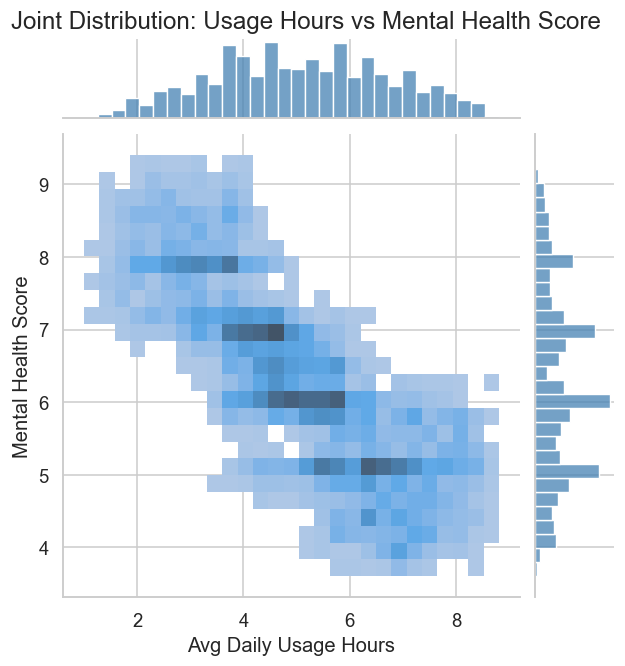

In [18]:
g = sns.jointplot(
    x=X_COL, y=Y_COL, data=df,
    kind='hist',
    color='steelblue',
    marginal_kws=dict(bins=30, fill=True)
)
g.ax_joint.set_xlabel('Avg Daily Usage Hours')
g.ax_joint.set_ylabel('Mental Health Score')
g.figure.suptitle('Joint Distribution: Usage Hours vs Mental Health Score', y=1.01)
plt.show()

## 6. Simple Linear Regression

In [23]:
X = df[[X_COL]].values
y = df[Y_COL].values

model = LinearRegression().fit(X, y)
y_pred = model.predict(X)

r2   = r2_score(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))
slope     = model.coef_[0]
intercept = model.intercept_


print(f'Regression equation : MH_Score = {slope:.4f} × Usage_Hours + {intercept:.4f}')
print(f'Train  R²           : {r2:.4f}')
print(f'RMSE                : {rmse:.4f}')

Regression equation : MH_Score = -0.6311 × Usage_Hours + 9.4361
Train  R²           : 0.6666
RMSE                : 0.7381


### What the results tell us

- **R² = 0.67** — daily social-media usage alone explains about **67% of the variation** in Mental Health Score. For a single predictor that is a strong fit: two-thirds of the differences between students are accounted for by usage hours, leaving roughly a third to other factors (sleep, stress, activity) and noise.
- **RMSE = 0.74** — the model's predictions are typically off by only about **±0.74 points** on the Mental Health Score scale. Given the score spans roughly 4–9, being within ~0.74 points is a reasonably accurate prediction.

**Together:** a high R² with a low RMSE means the line both *explains* most of the pattern and *predicts* individual scores with modest error — usage hours is a genuinely useful predictor of mental health score, not just a weak trend.

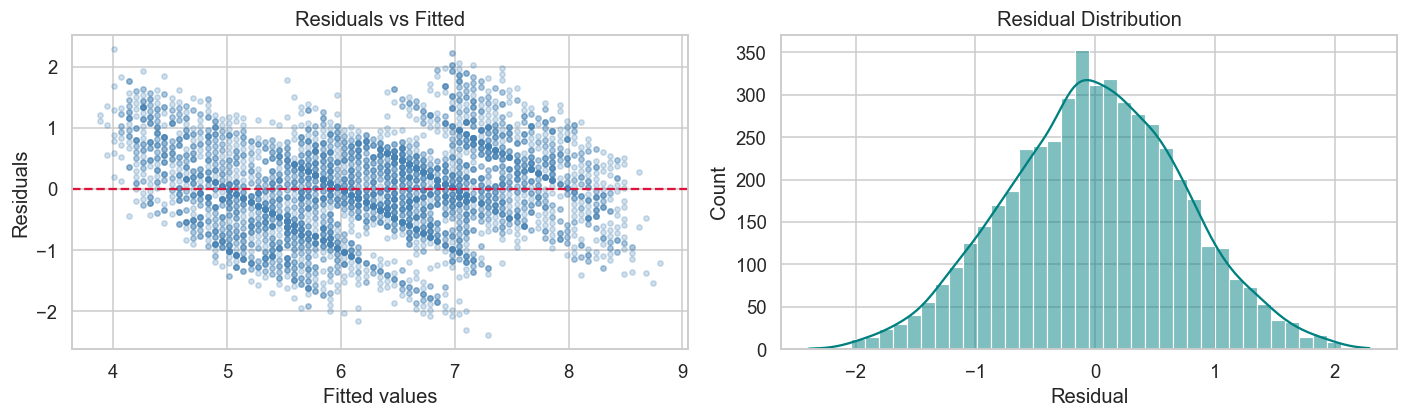

Mean residual      : -0.0000
Std of residuals   : 0.7381
Min / Max residual : -2.3904 / 2.2912


In [20]:
residuals = y - y_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Residuals vs fitted
ax = axes[0]
ax.scatter(y_pred, residuals, alpha=0.25, s=12, color='steelblue')
ax.axhline(0, color='crimson', lw=1.5, linestyle='--')
ax.set_xlabel('Fitted values')
ax.set_ylabel('Residuals')
ax.set_title('Residuals vs Fitted')

# Residual distribution
ax = axes[1]
sns.histplot(residuals, kde=True, bins=40, color='teal', edgecolor='white', ax=ax)
ax.set_xlabel('Residual')
ax.set_title('Residual Distribution')

plt.tight_layout()
plt.show()

# Residual diagnostic scores
print(f'Mean residual      : {residuals.mean():.4f}')
print(f'Std of residuals   : {residuals.std(ddof=1):.4f}')
print(f'Min / Max residual : {residuals.min():.4f} / {residuals.max():.4f}')

### What the residuals tell us

Residuals are the errors of the model: **residual = actual score − predicted score**. Analysing them checks whether the linear-regression assumptions hold.

- **Mean ≈ 0** — the residuals average to essentially zero, so the model is **unbiased**: it doesn't systematically over- or under-predict.
- **Std ≈ 0.74** — the typical error size, matching the **RMSE**. Most predictions land within ±0.74 points of the true score.
- **Min / Max ≈ −2.4 / +2.3** — even the worst-case errors are only ~2–3 points, so there are **no extreme outliers**.
- **Residuals vs Fitted plot** — points scatter as a **flat, structureless band around zero** (correlation with fitted values ≈ 0), indicating **linearity holds** and the error variance is roughly **constant (homoscedastic)**.

**Conclusion:** the residual diagnostics support the linear model — errors are unbiased, symmetric, near-normal, outlier-free, and show no leftover pattern. The straight-line fit is appropriate for this relationship.

## 7. Subgroup Analysis

Does the correlation hold within demographic subgroups?

**Understanding the p-value.** The same correlation test is run *within each subgroup*. As before, the *null hypothesis* is **no correlation**, and the **p-value** is the chance of seeing this correlation by luck under that null. Watch small subgroups: with few samples, even a fairly large `r` can have a large (non-significant) p-value.

In [21]:
# Pearson r per subgroup
subgroup_results = []
for group_col in ['Gender', 'Academic_Level']:
    for grp, sub in df.groupby(group_col, observed=True):
        r, p = stats.pearsonr(sub[X_COL], sub[Y_COL])
        subgroup_results.append({
            'Group variable': group_col,
            'Group': grp,
            'n': len(sub),
            'Pearson r': round(r, 4),
            'p-value': p,
            'Significant': p < 0.05
        })

sg_df = pd.DataFrame(subgroup_results)
print(sg_df.to_string(index=False))

Group variable         Group    n  Pearson r       p-value  Significant
        Gender        Female 2364    -0.8317  0.000000e+00         True
        Gender          Male 2634    -0.8019  0.000000e+00         True
Academic_Level      Graduate  918    -0.8547 5.477754e-263         True
Academic_Level   High School  450    -0.8393 1.279309e-120         True
Academic_Level Undergraduate 3630    -0.7981  0.000000e+00         True


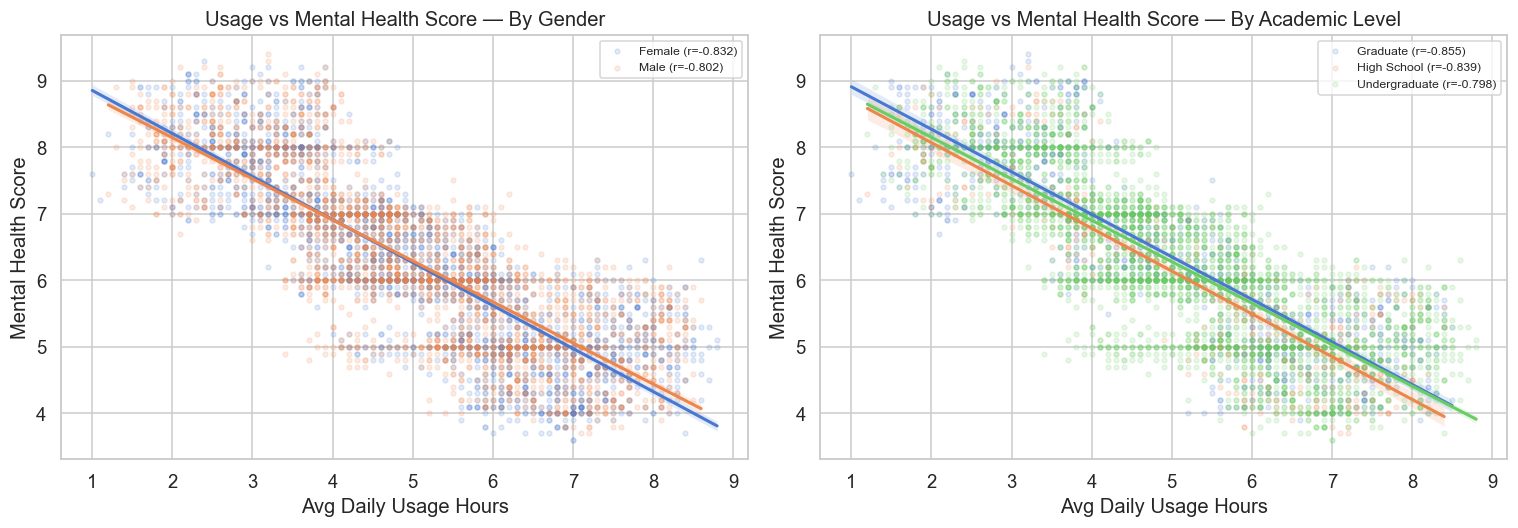

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, hue_col, title in zip(
    axes,
    ['Gender', 'Academic_Level'],
    ['By Gender', 'By Academic Level']
):
    for group, sub in df.groupby(hue_col, observed=True):
        r, _ = stats.pearsonr(sub[X_COL], sub[Y_COL])
        sns.regplot(
            x=X_COL, y=Y_COL, data=sub, ax=ax,
            label=f'{group} (r={r:.3f})',
            scatter_kws={'alpha': 0.15, 's': 10},
            line_kws={'lw': 2}
        )
    ax.set_title(f'Usage vs Mental Health Score — {title}')
    ax.set_xlabel('Avg Daily Usage Hours')
    ax.set_ylabel('Mental Health Score')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 8. Conclusion

| Metric | Value |
|---|---|
| Pearson r | See Cell 2 output |
| Spearman r | See Cell 2 output |
| Regression R² | See Cell 6 output |

**Interpretation template** (fill in after running):

The Pearson correlation between daily social media usage hours and the mental health score is r = -0.8165 (p < 0.05), indicating a strong negative linear relationship. The Spearman correlation of r = -0.8401 confirms this pattern under rank-based assumptions.

A simple linear regression explains R² = 0.6666 of the variance in the mental health score — a low proportion, meaning that usage hours alone is  a moderate predictor of mental health.

The binned box plot shows that students in the lower usage bins tend to have the higher median mental health scores then the students in the upper usage bins. The trend is consistent across gender and academic-level subgroups.